# Data Science: Course Assignment 2

The company "Urban Trends" is a rising start in the retail industry, focusing on a wide range of products from electronics to fashion and home goods. Being founded in Denmark the company quickly extended into multiple cities accross the country and abroad, building up presence through different retail stores. To keep their stores stocked and their supply chain running smoothly Urban Trends has partnered with a variety of suppliers.

Over the past few years the company has collected valuable sales data but struggled to extract any actionable insights from it. For example, Urban Trends would like to optimise their product offerings, improve their inventory levels and understand their customer better.

As a data scientist your role is to extract any valueable insights from the provided data, uncovering patterns, trends, inefficiencies and finally provide recommendations to improve Urban Trends' operations. For this you are provided with two datasets.

### Product Dataset Description
The product dataset contains all the different products Urban Trends is selling accross their stores:
- **SKU**: The stock keeping unit (SKU) is a unique code that is assigned to a product to track its sales, inventory, etc.
- **Product Name**: The name of the product.
- **Product Family**: The category that the product is placed in.
- **Sale Price**: The net price that the product is sold for (in DKK). The price is consistent across all stores and locations.
- **COGS**: The cost of goods sold (COGS) are the costs assiciated with selling the product (in DKK). The COGS is consistent across all stores and locations.
- **Supplier**: The name of the supplier that delivers the product. Note that some products can be acquired from multiple suppliers
- **Replenishment Time**: The time between ordering from the supplier until the delivery hits the store (in days).
- **Replenishment Frequency**: The time interval between placing individual orders (in days).

### Invoice Dataset Description
The invoice dataset contains all invoices across all stores that were generated over the past 2 years in daily frequency:
- **Invoive number**: Unique number associated with a single invoice. Note that an invoice can contain sales for multiple products.
- **Date**: The data at which the invoice was generated.
- **Store**: The store name at which the invoice was generated. Note that some stores are in multiple locations.
- **Store Location**: The location of the store at which the invoice was generated.
- **SKU**: The SKU of the product that was sold.
- **Quantity**: The amount of products that were sold.

### Tasks

1. Which store and location sell the highest number of 'Socks (5-pack)'?
2. How much of the total sales is from the product 'Socks (5-pack)'? How does that look for revenue and profit? Does it makes sense to sell the product 'Socks (5-pack)' in all stores and locations?
3. Display the sales of the product 'Socks (5-pack)' over time. Does the sales include seasonality?
4. Compare the sales of 2024 and 2025 of the product 'Socks (5-pack)'. Can you see a trend?
5. Compare the starting stock and the restocking with the sales of the product 'Socks (5-pack)'. Is there a potential for over/understocking? What is the optimum order quantity of the product 'Socks (5-pack)'?
6. Which insights can you get from the provided data?

Submitted by group 10 in Data Science (E26): 
Participants in alphabetical order: 
- Anamika Kamal 
- Jakub Swierzko
- Klavs Zile
- Krzysztof Sekulski
- Md Ragib Shahriyear
- Saif Ur Rehman 


# Note: 

We are using Socks (5-pack) for all six tasks. One unit below means one pack of socks. 

### Loading and preparing the data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

products = pd.read_csv("data_products_10.csv")
invoices_raw = pd.read_csv("data_invoices_10.csv")
product = "Socks (5-pack)"




# Data cleanup
# Removeing repeated rows and rows where we cannot identify the sale properly.
duplicate_count = invoices_raw.duplicated().sum()
invoices = invoices_raw.drop_duplicates().dropna().copy()
missing_count = len(invoices_raw) - duplicate_count - len(invoices)
invoices["Date"] = pd.to_datetime(invoices["Date"])


# identifying numerical columns for calculation
number_columns = ["Invoice Number", "SKU", "Sales Quantity"]
assert np.isfinite(invoices[number_columns]).all().all()
assert invoices[number_columns].gt(0).all().all()
assert invoices[number_columns].mod(1).eq(0).all().all()
invoices[number_columns] = invoices[number_columns].astype(int)

for column in ["Store", "Store Location"]:
    invoices[column] = invoices[column].str.strip()
assert invoices["SKU"].isin(products["SKU"]).all()

print(f"Removed {duplicate_count} duplicate rows and {missing_count} incomplete rows.")
print(f"Rows used: {len(invoices):,}")
print(f"Dates: {invoices['Date'].min():%Y-%m-%d} to {invoices['Date'].max():%Y-%m-%d}")

Removed 84 duplicate rows and 84 incomplete rows.
Rows used: 83,623
Dates: 2024-01-01 to 2025-12-31


In [3]:
# backpack has two suppliers, so joining the catalogue directly would count its sales twice.

for column in ["Product Name", "Sale Price"]:
    assert products.groupby("SKU")[column].nunique().eq(1).all()


# using lookup table so that we don't count sales twice
product_lookup = products.groupby("SKU", as_index=False).agg(
    **{"Product Name": ("Product Name", "first"),
       "Sale Price": ("Sale Price", "first"),
       "COGS min": ("COGS", "min"),
       "COGS max": ("COGS", "max")}
)
sales = invoices.merge(product_lookup, on="SKU", how="left", validate="many_to_one")
assert len(sales) == len(invoices)



sales["Revenue"] = sales["Sales Quantity"] * sales["Sale Price"]

sales["Gross profit lower"] = sales["Sales Quantity"] * (sales["Sale Price"] - sales["COGS max"])

sales["Gross profit upper"] = sales["Sales Quantity"] * (sales["Sale Price"] - sales["COGS min"])

socks = sales.loc[sales["Product Name"].eq(product)].copy()

socks_product = products.loc[products["Product Name"].eq(product)].iloc[0]

assert not socks.empty
assert products.loc[products["Product Name"].eq(product), "COGS"].nunique() == 1


display(products.loc[products["Product Name"].eq(product)])

,SKU,Product Name,Product Family,Sale Price,Supplier,COGS,Replenishment Time,Replenishment Frequency,Product Emissions,Transportation Emissions,Start Stock
0,7,Socks (5-pack),Apparel,150,CozyWear Clothing,45,10,6,4.2,70,31


The socks cost **45 DKK** and sell for **150 DKK** per pack, giving **105 DKK gross profit**
per pack. Here, profit means revenue minus COGS. Other costs such as rent, wages and other operating costs
are not included.

### 1. Which store and location sell the most socks?

,,Packs_sold,Revenue_DKK,Gross_profit_DKK
Store,Store Location,,,
Strand & Co.,Copenhagen,6658,998700,699090
TrendStop,Copenhagen,6219,932850,652995
Northern & Co.,Copenhagen,6165,924750,647325
Nordic House,Odense,4456,668400,467880
Prime Goods,Vejle,3323,498450,348915


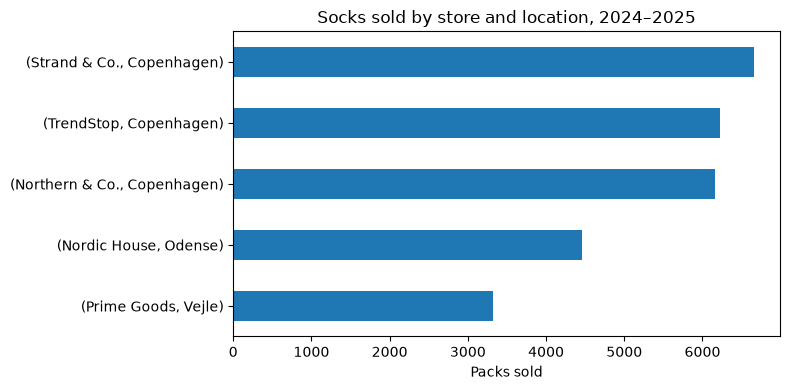

In [4]:
store_columns = ["Store", "Store Location"]

store_summary = socks.groupby(store_columns).agg(
    Packs_sold=("Sales Quantity", "sum"),
    Revenue_DKK=("Revenue", "sum"),
    Gross_profit_DKK=("Gross profit lower", "sum")
).sort_values("Packs_sold", ascending=False)

display(store_summary)

store_summary["Packs_sold"].sort_values().plot.barh(figsize=(8, 4))

# PLOTTING STORE BY STORE 
plt.title("Socks sold by store and location, 2024–2025")
plt.xlabel("Packs sold")
plt.ylabel("")
plt.tight_layout()
plt.show()

Answer of question 1: Strand & Co. in Copenhagen sells the most socks, with 6658 packs. 

### 2. Share of sales, revenue and profit

Assuming sales==number of units sold. Let's also calculate revenue and gross
profit because products have different prices and costs.

In [5]:
socks_profit = socks["Gross profit lower"].sum()

company_profit_lower = sales["Gross profit lower"].sum()

company_profit_upper = sales["Gross profit upper"].sum()


# new dataframe 
contribution = pd.DataFrame({
    "Measure": ["Units sold", "Revenue (DKK)", "Gross profit (DKK)"],
    "Socks": [socks["Sales Quantity"].sum(), socks["Revenue"].sum(), socks_profit],
    "Company lower": [sales["Sales Quantity"].sum(), sales["Revenue"].sum(), company_profit_lower],
    "Company upper": [sales["Sales Quantity"].sum(), sales["Revenue"].sum(), company_profit_upper]
})


# The larger company profit gives the smaller socks profit share.

contribution["Socks share lower (%)"] = 100 * contribution["Socks"] / contribution["Company upper"]

contribution["Socks share upper (%)"] = 100 * contribution["Socks"] / contribution["Company lower"]

display(contribution.round(2))

store_summary["Share of store unit sales (%)"] = (
    100 * store_summary["Packs_sold"] / sales.groupby(store_columns)["Sales Quantity"].sum()
)

display(store_summary.round(2))

,Measure,Socks,Company lower,Company upper,Socks share lower (%),Socks share upper (%)
0,Units sold,26821,114072,114072,23.51,23.51
1,Revenue (DKK),4023150,24593400,24593400,16.36,16.36
2,Gross profit (DKK),2816205,15414060,15540060,18.12,18.27


,,Packs_sold,Revenue_DKK,Gross_profit_DKK,Share of store unit sales (%)
Store,Store Location,,,,
Strand & Co.,Copenhagen,6658,998700,699090,23.99
TrendStop,Copenhagen,6219,932850,652995,23.16
Northern & Co.,Copenhagen,6165,924750,647325,23.01
Nordic House,Odense,4456,668400,467880,23.70
Prime Goods,Vejle,3323,498450,348915,23.94


Answer of question 2: socks account for 23.51% of all units sold, 16.36% of revenue and
18.12–18.27% of gross profit. they generate 4023150 DKK revenue and
2816205 DKK gross profit, with a 70% gross margin.

Keeping socks in all five stores looks reasonable: every store sells them, and socks
make up about 23–24% of each store's unit sales. 

### 3. Sales over time and seasonality

let's plot monthly totals and compare average daily sales by month. 

If a store records other products but no socks on a date, we count zero socks sales. 
If it records nothing at all, we will leave that store-date unknowm. 

all-store daily averages use only dates with activity in every store, so missing activity is not treated as zero demans. 

Dates with activity in every store: 726 of 731
Unknown store-dates: 5


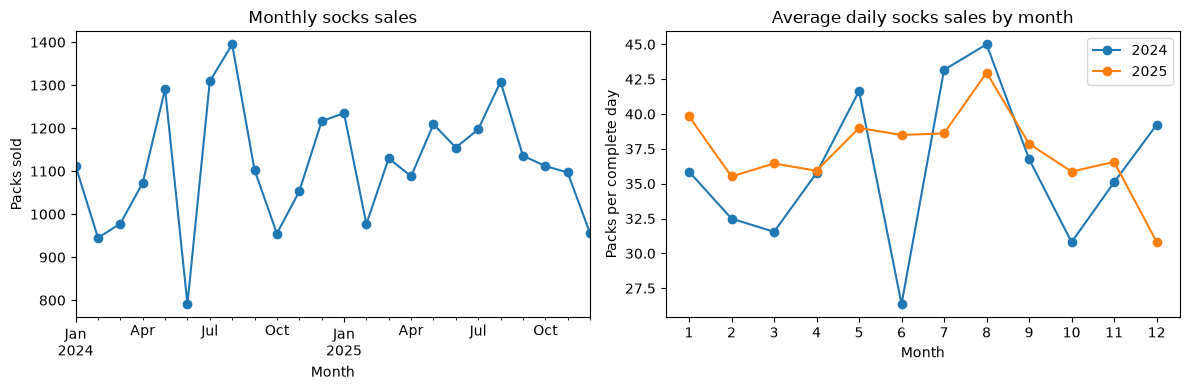

,2024,2025
Month,,
1,35.87,39.84
2,32.50,35.52
3,31.55,36.45
4,35.77,35.93
5,41.65,39.00
6,26.37,38.50
7,43.17,38.61
8,45.00,42.97
9,36.77,37.87


In [6]:
calendar = pd.date_range(sales["Date"].min(), sales["Date"].max(), freq="D")

activity = (sales.groupby(["Date"] + store_columns).size()
            .unstack(store_columns).reindex(calendar))

daily_socks = (socks.groupby(["Date"] + store_columns)["Sales Quantity"].sum()
               .unstack(store_columns)
               .reindex(index=calendar, columns=activity.columns)
               .fillna(0).where(activity.notna()))

all_store_daily = daily_socks.sum(axis=1, min_count=daily_socks.shape[1])

print("Dates with activity in every store:", all_store_daily.count(), "of", len(calendar))

print("Unknown store-dates:", activity.isna().sum().sum())

monthly_sales = socks.set_index("Date")["Sales Quantity"].resample("MS").sum()

monthly_daily_mean = all_store_daily.groupby(
    [all_store_daily.index.month, all_store_daily.index.year]
).mean().unstack()

monthly_daily_mean.index.name = "Month"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

monthly_sales.plot(ax=axes[0], marker="o")
axes[0].set(title="Monthly socks sales", xlabel="Month", ylabel="Packs sold")

monthly_daily_mean.plot(ax=axes[1], marker="o")
axes[1].set(title="Average daily socks sales by month", xlabel="Month", ylabel="Packs per complete day")

axes[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

display(monthly_daily_mean.round(2))

In [7]:
# keeping large purchases, but let's find out how much they affect 

large_sale_cutoff = socks["Sales Quantity"].quantile(0.999)

large_sales = socks["Sales Quantity"].gt(large_sale_cutoff)

print(f"{large_sales.sum()} invoice lines exceed the 99.9th percentile ({large_sale_cutoff:.2f} packs).")
print(f"These lines contain {socks.loc[large_sales, 'Sales Quantity'].sum():,} packs.")
print(f"Largest single invoice line: {socks['Sales Quantity'].max()} packs.")

display(socks.loc[large_sales, ["Date", "Store", "Store Location", "Sales Quantity"]]
        .sort_values("Sales Quantity", ascending=False).head())

16 invoice lines exceed the 99.9th percentile (13.28 packs).
These lines contain 1,357 packs.
Largest single invoice line: 250 packs.


,Date,Store,Store Location,Sales Quantity
24873,2024-08-03,Strand & Co.,Copenhagen,250
15469,2024-05-16,TrendStop,Copenhagen,190
71693,2025-09-15,Strand & Co.,Copenhagen,149
66585,2025-08-02,Prime Goods,Vejle,95
46683,2025-02-12,TrendStop,Copenhagen,92


### 4. comparing 2024 and 2025

In [8]:
annual_sales = socks.groupby(socks["Date"].dt.year).agg(
    Packs_sold=("Sales Quantity", "sum"),
    Revenue_DKK=("Revenue", "sum"),
    Gross_profit_DKK=("Gross profit lower", "sum")
)

annual_sales["Complete days"] = all_store_daily.groupby(all_store_daily.index.year).count()

annual_sales["Packs per complete day"] = all_store_daily.groupby(all_store_daily.index.year).mean()

display(annual_sales.round(2))

unit_growth = 100 * (
    float(annual_sales.at[2025, "Packs_sold"]) / float(annual_sales.at[2024, "Packs_sold"]) - 1
)
daily_growth = 100 * (
    float(annual_sales.at[2025, "Packs per complete day"]) /
    float(annual_sales.at[2024, "Packs per complete day"]) - 1
)

print(f"Change in recorded packs sold: {unit_growth:+.2f}%")

print(f"Change in average packs per complete day: {daily_growth:+.2f}%")

# lets see whether the direction changes when the largest purchases are left out.

annual_without_large_sales = socks.loc[~large_sales].groupby(socks["Date"].dt.year)["Sales Quantity"].sum()

sensitivity_growth = 100 * (annual_without_large_sales.loc[2025] / annual_without_large_sales.loc[2024] - 1)

print(f"Change excluding the flagged large sales: {sensitivity_growth:+.2f}%")

,Packs_sold,Revenue_DKK,Gross_profit_DKK,Complete days,Packs per complete day
Date,,,,,
2024,13221,1983150,1388205,364,36.19
2025,13600,2040000,1428000,362,37.34


Change in recorded packs sold: +2.87%
Change in average packs per complete day: +3.19%
Change excluding the flagged large sales: +2.46%


### 5. Starting stock, replenishment and order quantity


,,Mean packs/day,Assumed starting packs,Starting cover (days),Expected sales in 10 days,Expected sales in 6 days,Suggested packs/order,Expected sales in 16 days
Store,Store Location,,,,,,,
Nordic House,Odense,6.11,31,5.07,61.12,36.67,37,97.80
Northern & Co.,Copenhagen,8.43,31,3.68,84.34,50.60,51,134.94
Prime Goods,Vejle,4.56,31,6.79,45.65,27.39,28,73.03
Strand & Co.,Copenhagen,9.11,31,3.40,91.08,54.65,55,145.73
TrendStop,Copenhagen,8.51,31,3.64,85.08,51.05,52,136.12


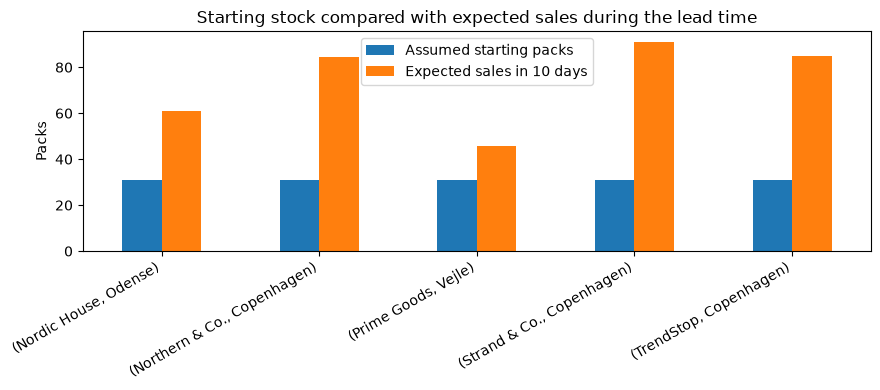

In [9]:
lead_time = int(socks_product["Replenishment Time"])


order_interval = int(socks_product["Replenishment Frequency"])

start_stock = int(socks_product["Start Stock"])

# Use each store's observed days rather than treating unknown days as zero.

mean_daily_sales = daily_socks.mean()

stock_comparison = pd.DataFrame({
    "Mean packs/day": mean_daily_sales,
    "Assumed starting packs": start_stock,
    "Starting cover (days)": start_stock / mean_daily_sales,
    "Expected sales in 10 days": mean_daily_sales * lead_time,
    "Expected sales in 6 days": mean_daily_sales * order_interval,
    "Suggested packs/order": np.ceil(mean_daily_sales * order_interval).astype(int),
    "Expected sales in 16 days": mean_daily_sales * (lead_time + order_interval)
})

display(stock_comparison.round(2))

stock_comparison[["Assumed starting packs", "Expected sales in 10 days"]].plot.bar(figsize=(9, 4))

plt.title("Starting stock compared with expected sales during the lead time")

plt.ylabel("Packs")

plt.xlabel("")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

Answer: Under the per-store assumption, 31 packs cover only 3.40–6.79 days of
average recorded sales. Expected sales during the 10-day lead time are 45.65–91.08
packs, so every store risks running out before its first delivery if no orders are
already on the way. If 31 packs are company-wide, coverage is even shorter.

A basic starting point is to order enough for the next six days:


### 6. Insights and recommendations

- keeping socks available in all stores. They contribute nearly a 1/4th of unit
  sales in each store and earn 105 DKK gross profit per pack. 

- adjusting stock by store: Strand & Co. sells about 9.11 packs per observed day,
  compared with 4.56 at Prime Goods. A single order quantity for all stores would
  ignore this difference.

- reviewing the starting stock: under the per-store assumption, 31 packs are below
  expected sales during the supplier's 10 day lead time in every store. checking
  outstanding orders and actual inventory before changing replenishment can be helpful. 

